# Leprosy vs Non-Leprosy Skin Disease Classification (نسخة نهائية مُصححة)
### EfficientNet-B3 + ConvNeXt-Tiny + ResNet50 + Soft-Voting Ensemble

**ملحوظة:** النسخة دي فيها كل الإصلاحات اللي اتفقنا عليها:
1. ✅ `organized_data` على القرص المحلي (`/content`) بدل Drive - سرعة عالية
2. ✅ تجميع الصور generic (بيدعم أي تداخل فولدرات زي `train/`, `test/` قبل اسم المرض)
3. ✅ أسماء فولدرات الجذام الصحيحة (بمسافات: `Leprosy Tuberculoid` ... إلخ)
4. ✅ فحص اتصال Drive + المساحة المتاحة قبل التدريب (سبب مشكلة الـ checkpoint الضائع)
5. ✅ EarlyStopping بيتأكد فعليًا إن الملف اتحفظ سليم بعد كل حفظ (مش بس يفترض النجاح)
6. ✅ خلية تشخيص شاملة بعد التدريب مباشرة قبل التقييم
7. ✅ مقارنة شاملة نهائية (Bar chart, ROC, Confusion Matrices grid, Training curves overlay, تعقيد الموديلات)

**ملحوظة:** الـ Stacking والـ Stratified K-Fold مؤجلين لمرحلة تانية بعد ما نطلّع نتايج الـ split اليدوي الحالي، عشان نقارن بينهم بعدين.

**قبل التشغيل:** Runtime -> Change runtime type -> GPU (T4 كفاية)


## 1) تركيب المكتبات المطلوبة

In [ ]:
!pip install -q torch torchvision scikit-learn pandas matplotlib seaborn

## 2) ربط Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3) الإعدادات (Config)
**عدّلي هنا:**
- `RAW_DATA_DIR`: مسار الداتاست الأصلية على Drive
- `LEPROSY_CLASS_NAMES`: أسماء فولدرات الجذام (مطابقة لأسمائها الحقيقية بمسافات)


In [ ]:
import os

# ---------------------------------------------------------------------
RAW_DATA_DIR = "/content/drive/MyDrive/Atlas dan ISIC2019 (31 classes)"

# ---------------------------------------------------------------------
# أسماء فولدرات الجذام الصحيحة (بمسافات - مطابقة للداتاست الفعلي)
# ---------------------------------------------------------------------
LEPROSY_CLASS_NAMES = [
    "Leprosy Tuberculoid",
    "Leprosy Lepromatous",
    "Leprosy Borderline",
]

# ---------------------------------------------------------------------
# الداتاست المنظمة (organized_data) على القرص المحلي بتاع Colab (/content)
# عشان تكون سريعة جدًا في النسخ والقراءة أثناء التدريب - مش على Drive
# (النسخ على Drive بطيء جدًا لآلاف الملفات الصغيرة: كل ملف = API call).
# تنويه: /content بيتمسح لو الـ session قفلت، فلو حصل كده رجعي شغلي خلية
# التنظيم (رقم 5) تاني - بتاخد دقيقة/دقيقتين بس على القرص المحلي.
# ---------------------------------------------------------------------
PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"
ORGANIZED_DATA_DIR = "/content/organized_data"
CHECKPOINTS_DIR = os.path.join(PROJECT_DIR, "outputs/checkpoints")
LOGS_DIR = os.path.join(PROJECT_DIR, "outputs/logs")
PLOTS_DIR = os.path.join(PROJECT_DIR, "outputs/plots")
RESULTS_DIR = os.path.join(PROJECT_DIR, "outputs/results")

for d in [ORGANIZED_DATA_DIR, CHECKPOINTS_DIR, LOGS_DIR, PLOTS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

# نسب التقسيم (Stratified) - split يدوي ثابت (K-Fold هيتضاف لاحقًا للمقارنة)
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
RANDOM_SEED = 42

# Hyperparameters
IMAGE_SIZE = 300
BATCH_SIZE = 16
NUM_EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.4
LABEL_SMOOTHING = 0.1
EARLY_STOPPING_PATIENCE = 8
LR_SCHEDULER_PATIENCE = 3
FREEZE_BACKBONE_EPOCHS = 5

MODEL_NAMES = ["efficientnet_b3", "convnext_tiny", "resnet50"]

print("الإعدادات جاهزة ✅")


الإعدادات جاهزة ✅


## 4) فحص Drive قبل أي حاجة (مهم جدًا - سبب مشكلة الـ checkpoint الضايع قبل كده)
بيتأكد إن Drive متصلة فعليًا (مش فولدر محلي وهمي) + إن فيه مساحة كافية،
عشان نتجنب تكرار مشكلة حفظ checkpoint ناقص/فاسد بصمت.

In [ ]:
import shutil

def gb(x):
    return x / (1024 ** 3)

# 1) هل Drive متصلة فعليًا؟
is_really_mounted = os.path.ismount("/content/drive")
print(f"هل Google Drive متصلة فعليًا؟ {is_really_mounted}")
if not is_really_mounted:
    print("⚠️  Drive مش متصلة! ارجعي شغّلي خلية drive.mount() فوق الأول.")
else:
    print("✅ Drive متصلة صح.")

# 2) هل فيه مساحة كافية؟
total, used, free = shutil.disk_usage("/content/drive/MyDrive")
print(f"\nمساحة Drive: الكلية={gb(total):.2f} GB | المستخدمة={gb(used):.2f} GB | المتاحة={gb(free):.2f} GB")

if gb(free) < 1:
    print("⚠️  تحذير: أقل من 1 GB متاح - احتمال كبير يفشل حفظ الـ checkpoints بصمت. فضّي مساحة الأول!")
elif gb(free) < 3:
    print("ℹ️  المساحة قليلة نسبيًا - يفضل تفرغي مساحة أكتر قبل التدريب.")
else:
    print("✅ المساحة كويسة.")


هل Google Drive متصلة فعليًا؟ True
✅ Drive متصلة صح.

مساحة Drive: الكلية=15.00 GB | المستخدمة=4.99 GB | المتاحة=10.01 GB
✅ المساحة كويسة.


## 5) تنظيم الداتا وتقسيمها (Leprosy مقابل Non-Leprosy)
دالة عامة (generic) بتدعم أي تداخل فولدرات (زي `RAW_DATA_DIR/train/<class>` و
`RAW_DATA_DIR/test/<class>`) وبتدمجهم مع بعض وتعمل تقسيمنا الخاص (70/15/15).

In [ ]:
!pip install -q tqdm

In [ ]:
import shutil as _shutil
import random
from collections import defaultdict
import pandas as pd
from sklearn.model_selection import train_test_split

VALID_EXTS = (".jpg", ".jpeg", ".png", ".bmp")
random.seed(RANDOM_SEED)


def recommend_split(n_minority_class: int):
    if n_minority_class < 80:
        print(f"⚠️  تحذير: عدد صور الجذام قليل جدًا ({n_minority_class} صورة).")
        print("   ينصح باستخدام Stratified K-Fold Cross Validation (k=5) بدل split ثابت.")
    elif n_minority_class < 150:
        print(f"ℹ️  عدد صور الجذام ({n_minority_class}) متوسط - 70/15/15 مقبول، زوّدي augmentation.")
    else:
        print(f"✅ عدد صور الجذام ({n_minority_class}) كافي - تقسيم 70/15/15 آمن.")


def collect_images_by_label():
    """
    عامة (generic): بتمشي جوه RAW_DATA_DIR بأي مستوى تداخل (os.walk) وبتعتبر
    أي فولدر لقيت فيه صور مباشرة هو اسم كلاس. بتدعم شكل:
    RAW_DATA_DIR/train/<class>/*.jpg  و  RAW_DATA_DIR/test/<class>/*.jpg
    (بندمج train/test الأصليين مع بعض ونعمل تقسيمنا الخاص).
    """
    images = defaultdict(list)
    found_any = False
    for root, dirs, files in os.walk(RAW_DATA_DIR):
        image_files = [f for f in files if f.lower().endswith(VALID_EXTS)]
        if not image_files:
            continue
        found_any = True
        class_name = os.path.basename(root)
        label = "leprosy" if class_name in LEPROSY_CLASS_NAMES else "non_leprosy"
        for fname in image_files:
            images[label].append(os.path.join(root, fname))
    if not found_any:
        raise FileNotFoundError(f"مفيش صور اتلقت جوه {RAW_DATA_DIR} بأي مستوى. تأكدي من المسار والصيغ.")
    return images


def stratified_split(paths, ratios, seed):
    train_ratio, val_ratio, test_ratio = ratios
    train_paths, temp_paths = train_test_split(paths, train_size=train_ratio, random_state=seed)
    val_relative = val_ratio / (val_ratio + test_ratio)
    val_paths, test_paths = train_test_split(temp_paths, train_size=val_relative, random_state=seed)
    return train_paths, val_paths, test_paths


from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.notebook import tqdm

def copy_files(paths, dest_dir):
    os.makedirs(dest_dir, exist_ok=True)

    def _copy_one(src):
        original_class = os.path.basename(os.path.dirname(src)).replace(" ", "_")
        new_name = f"{original_class}__{os.path.basename(src)}"
        _shutil.copy2(src, os.path.join(dest_dir, new_name))

    with ThreadPoolExecutor(max_workers=16) as executor:
        futures = [executor.submit(_copy_one, src) for src in paths]
        for _ in tqdm(as_completed(futures), total=len(futures), desc=f"نسخ إلى {os.path.basename(dest_dir)}"):
            pass


print("=" * 70)
print("جاري قراءة الداتاست الأصلية...")
images_by_label = collect_images_by_label()
n_leprosy = len(images_by_label["leprosy"])
n_non_leprosy = len(images_by_label["non_leprosy"])
print(f"عدد صور الجذام (كل الأنواع مجمّعة): {n_leprosy}")
print(f"عدد صور باقي الأمراض (30 كلاس): {n_non_leprosy}")
print("=" * 70)
recommend_split(n_leprosy)

summary_rows = []
ratios = (TRAIN_RATIO, VAL_RATIO, TEST_RATIO)

for label, paths in images_by_label.items():
    train_p, val_p, test_p = stratified_split(paths, ratios, RANDOM_SEED)
    splits = {"train": train_p, "val": val_p, "test": test_p}
    for split_name, split_paths in splits.items():
        dest = os.path.join(ORGANIZED_DATA_DIR, split_name, label)
        copy_files(split_paths, dest)
        summary_rows.append({"Split": split_name, "Class": label, "Number_of_Images": len(split_paths)})

summary_df = pd.DataFrame(summary_rows)
pivot = summary_df.pivot(index="Split", columns="Class", values="Number_of_Images").reindex(["train", "val", "test"])
pivot["Total"] = pivot.sum(axis=1)

print("\n" + "=" * 70)
print("جدول توزيع الصور بعد التقسيم (Train / Val / Test):")
print("=" * 70)
print(pivot.to_string())

csv_path = os.path.join(RESULTS_DIR, "data_split_summary.csv")
pivot.to_csv(csv_path)
print(f"\nتم حفظ الجدول في: {csv_path}")
pivot


جاري قراءة الداتاست الأصلية...
عدد صور الجذام (كل الأنواع مجمّعة): 672
عدد صور باقي الأمراض (30 كلاس): 4237
✅ عدد صور الجذام (672) كافي - تقسيم 70/15/15 آمن.


نسخ إلى non_leprosy:   0%|          | 0/2965 [00:00<?, ?it/s]

نسخ إلى non_leprosy:   0%|          | 0/636 [00:00<?, ?it/s]

نسخ إلى non_leprosy:   0%|          | 0/636 [00:00<?, ?it/s]

نسخ إلى leprosy:   0%|          | 0/470 [00:00<?, ?it/s]

نسخ إلى leprosy:   0%|          | 0/101 [00:00<?, ?it/s]

نسخ إلى leprosy:   0%|          | 0/101 [00:00<?, ?it/s]


جدول توزيع الصور بعد التقسيم (Train / Val / Test):
Class  leprosy  non_leprosy  Total
Split                             
train      470         2965   3435
val        101          636    737
test       101          636    737

تم حفظ الجدول في: /content/drive/MyDrive/skin_disease_project/outputs/results/data_split_summary.csv


Class,leprosy,non_leprosy,Total
Split,,,
train,470,2965,3435
val,101,636,737
test,101,636,737


## 6) DataLoaders + Data Augmentation + Weighted Sampler

In [ ]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def get_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=20),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.9, 1.1)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.15),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    return train_transform, eval_transform


def build_weighted_sampler(dataset):
    targets = [label for _, label in dataset.samples]
    class_counts = torch.bincount(torch.tensor(targets))
    class_weights = 1.0 / class_counts.float()
    sample_weights = [class_weights[t] for t in targets]
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)


def get_dataloaders():
    train_transform, eval_transform = get_transforms()
    train_dir = os.path.join(ORGANIZED_DATA_DIR, "train")
    val_dir = os.path.join(ORGANIZED_DATA_DIR, "val")
    test_dir = os.path.join(ORGANIZED_DATA_DIR, "test")

    train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
    val_dataset = datasets.ImageFolder(val_dir, transform=eval_transform)
    test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

    assert train_dataset.classes == val_dataset.classes == test_dataset.classes, \
        "ترتيب الكلاسات مختلف بين train/val/test"

    print(f"الكلاسات: {train_dataset.classes}")

    sampler = build_weighted_sampler(train_dataset)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

    return train_loader, val_loader, test_loader, train_dataset.classes


train_loader, val_loader, test_loader, CLASSES = get_dataloaders()
LEPROSY_INDEX = CLASSES.index("leprosy")
print(f"index كلاس الجذام = {LEPROSY_INDEX}")


الكلاسات: ['leprosy', 'non_leprosy']
index كلاس الجذام = 0


## 7) Model Factory

In [ ]:
import torch.nn as nn
from torchvision import models

NUM_CLASSES = 2

def build_model(model_name: str):
    if model_name == "efficientnet_b3":
        model = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        backbone = model.features
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=DROPOUT_RATE, inplace=True),
            nn.Linear(in_features, NUM_CLASSES),
        )
    elif model_name == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        backbone = model.features
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(p=DROPOUT_RATE, inplace=False),
            nn.Linear(in_features, NUM_CLASSES),
        )
    elif model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        backbone = nn.Sequential(*list(model.children())[:-2])
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(p=DROPOUT_RATE),
            nn.Linear(in_features, NUM_CLASSES),
        )
    else:
        raise ValueError(f"موديل غير معروف: {model_name}")
    return model, backbone


def set_backbone_trainable(backbone, trainable: bool):
    for param in backbone.parameters():
        param.requires_grad = trainable

print("Model factory جاهز ✅")


Model factory جاهز ✅


## 8) EarlyStopping (مع تحقق فوري من سلامة الملف) + دالة التدريب العامة
**التعديل المهم هنا:** بعد كل `torch.save`، الكود بيحاول يعيد تحميل الملف فورًا
للتأكد إنه اتحفظ سليم (مش تالف/ناقص بسبب امتلاء مساحة Drive). لو فشل، بيطبع
تحذير واضح **وقت التدريب نفسه** بدل ما نكتشف المشكلة بعد ساعات في التقييم.

In [ ]:
import time
import json
import numpy as np
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt


def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

DEVICE = get_device()
print(f"الجهاز المستخدم: {DEVICE}  (لازم يكون cuda - تأكدي من Runtime type)")


class EarlyStopping:
    def __init__(self, patience=8, checkpoint_path="best_model.pt"):
        self.patience = patience
        self.checkpoint_path = checkpoint_path
        self.best_loss = np.inf
        self.counter = 0
        self.should_stop = False

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0

            # ---- الحفظ + التحقق الفوري من سلامة الملف ----
            torch.save(model.state_dict(), self.checkpoint_path)
            try:
                _ = torch.load(self.checkpoint_path, map_location="cpu")
                file_size_mb = os.path.getsize(self.checkpoint_path) / (1024 ** 2)
                if file_size_mb < 5:
                    print(f"   ⚠️  تحذير: حجم الملف صغير جدًا ({file_size_mb:.2f} MB) - احتمال كتابة ناقصة!")
                    return False
            except Exception as e:
                print(f"   ❌ فشل التحقق من الملف بعد الحفظ: {e}")
                print("   السبب الأرجح: مساحة Drive ممتلئة وقت الحفظ.")
                return False

            return True
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False


def overfitting_gap_warning(train_acc, val_acc, threshold=10.0):
    gap = train_acc - val_acc
    if gap > threshold:
        print(f"   ⚠️  تحذير Overfitting: الفرق بين train_acc و val_acc = {gap:.1f}%")


def run_epoch(model, loader, criterion, optimizer, device, train_mode: bool):
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(train_mode)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if train_mode:
            optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        if train_mode:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total


def train_one_model(model_name):
    print(f"\n{'='*70}\nجاري تدريب: {model_name}\n{'='*70}")
    model, backbone = build_model(model_name)
    model.to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=LR_SCHEDULER_PATIENCE)

    checkpoint_path = os.path.join(CHECKPOINTS_DIR, f"{model_name}_best.pt")
    early_stopping = EarlyStopping(patience=EARLY_STOPPING_PATIENCE, checkpoint_path=checkpoint_path)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    set_backbone_trainable(backbone, trainable=False)
    print(f"[Phase 1] الـ backbone مجمد لأول {FREEZE_BACKBONE_EPOCHS} epochs")

    start_time = time.time()
    for epoch in range(1, NUM_EPOCHS + 1):
        if epoch == FREEZE_BACKBONE_EPOCHS + 1:
            set_backbone_trainable(backbone, trainable=True)
            print(f"[Phase 2] فك تجميد الـ backbone من epoch {epoch}")

        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, DEVICE, True)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer, DEVICE, False)
        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        improved = early_stopping(val_loss, model)
        flag = " ✅ (best - saved & verified)" if improved else ""
        print(f"Epoch {epoch:03d} | train_loss={train_loss:.4f} acc={train_acc:.2f}% | "
              f"val_loss={val_loss:.4f} acc={val_acc:.2f}%{flag}")
        overfitting_gap_warning(train_acc, val_acc)

        if early_stopping.should_stop:
            print(f"⏹️  Early stopping عند epoch {epoch}")
            break

    print(f"انتهى التدريب في {(time.time()-start_time)/60:.1f} دقيقة. أفضل val_loss={early_stopping.best_loss:.4f}")

    with open(os.path.join(LOGS_DIR, f"{model_name}_history.json"), "w") as f:
        json.dump(history, f, indent=2)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"{model_name} - Loss"); axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train Acc")
    axes[1].plot(history["val_acc"], label="Val Acc")
    axes[1].set_title(f"{model_name} - Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"{model_name}_curves.png"), dpi=150)
    plt.show()

    return history

print("دالة التدريب جاهزة ✅ (مع تحقق سلامة الملف بعد كل حفظ)")


الجهاز المستخدم: cuda  (لازم يكون cuda - تأكدي من Runtime type)
دالة التدريب جاهزة ✅ (مع تحقق سلامة الملف بعد كل حفظ)


## 9) تدريب EfficientNet-B3


جاري تدريب: efficientnet_b3
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 258MB/s]


[Phase 1] الـ backbone مجمد لأول 5 epochs
Epoch 001 | train_loss=0.6385 acc=67.28% | val_loss=0.5969 acc=68.39% ✅ (best - saved & verified)
Epoch 002 | train_loss=0.5678 acc=74.99% | val_loss=0.6142 acc=64.72%
   ⚠️  تحذير Overfitting: الفرق بين train_acc و val_acc = 10.3%
Epoch 003 | train_loss=0.5503 acc=75.87% | val_loss=0.5601 acc=70.28% ✅ (best - saved & verified)
Epoch 004 | train_loss=0.5395 acc=75.84% | val_loss=0.5598 acc=70.69% ✅ (best - saved & verified)
Epoch 005 | train_loss=0.5277 acc=76.74% | val_loss=0.5564 acc=71.37% ✅ (best - saved & verified)
[Phase 2] فك تجميد الـ backbone من epoch 6
Epoch 006 | train_loss=0.4262 acc=85.71% | val_loss=0.3510 acc=90.09% ✅ (best - saved & verified)
Epoch 007 | train_loss=0.3461 acc=91.53% | val_loss=0.3158 acc=92.67% ✅ (best - saved & verified)
Epoch 008 | train_loss=0.3148 acc=93.74% | val_loss=0.2963 acc=94.71% ✅ (best - saved & verified)
Epoch 009 | train_loss=0.2904 acc=95.31% | val_loss=0.2893 acc=94.17% ✅ (best - saved & verifie

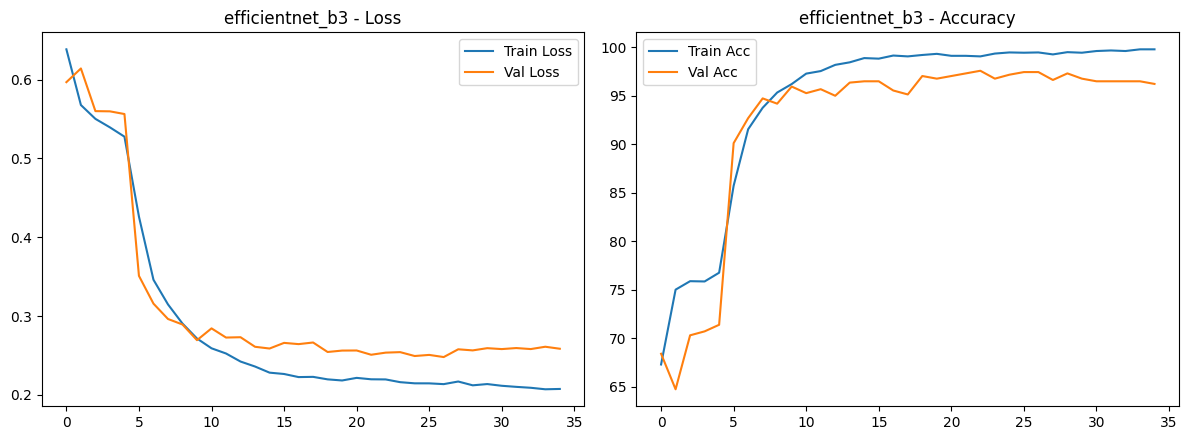

In [ ]:
history_efficientnet = train_one_model("efficientnet_b3")

## 10) تدريب ConvNeXt-Tiny


جاري تدريب: convnext_tiny
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 236MB/s] 


[Phase 1] الـ backbone مجمد لأول 5 epochs
Epoch 001 | train_loss=0.5619 acc=73.65% | val_loss=0.5498 acc=69.74% ✅ (best - saved & verified)
Epoch 002 | train_loss=0.4989 acc=79.77% | val_loss=0.5075 acc=75.44% ✅ (best - saved & verified)
Epoch 003 | train_loss=0.4725 acc=81.63% | val_loss=0.5536 acc=71.37%
   ⚠️  تحذير Overfitting: الفرق بين train_acc و val_acc = 10.3%
Epoch 004 | train_loss=0.4652 acc=81.92% | val_loss=0.4947 acc=77.75% ✅ (best - saved & verified)
Epoch 005 | train_loss=0.4625 acc=83.20% | val_loss=0.5238 acc=75.71%
[Phase 2] فك تجميد الـ backbone من epoch 6
Epoch 006 | train_loss=0.3877 acc=88.47% | val_loss=0.3213 acc=92.94% ✅ (best - saved & verified)
Epoch 007 | train_loss=0.3011 acc=94.18% | val_loss=0.2639 acc=96.34% ✅ (best - saved & verified)
Epoch 008 | train_loss=0.2728 acc=95.75% | val_loss=0.2702 acc=96.07%
Epoch 009 | train_loss=0.2627 acc=96.74% | val_loss=0.3129 acc=92.27%
Epoch 010 | train_loss=0.2417 acc=97.85% | val_loss=0.2435 acc=97.96% ✅ (best - s

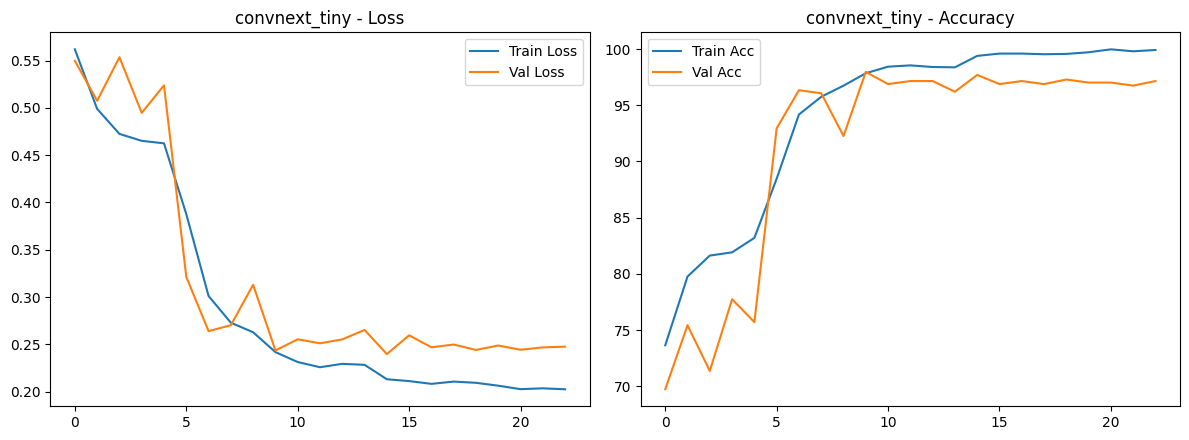

In [ ]:
history_convnext = train_one_model("convnext_tiny")

## 11) تدريب ResNet50


جاري تدريب: resnet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 231MB/s]


[Phase 1] الـ backbone مجمد لأول 5 epochs
Epoch 001 | train_loss=0.6406 acc=67.39% | val_loss=0.5932 acc=75.31% ✅ (best - saved & verified)
Epoch 002 | train_loss=0.5560 acc=77.79% | val_loss=0.5720 acc=71.10% ✅ (best - saved & verified)
Epoch 003 | train_loss=0.5312 acc=78.54% | val_loss=0.5391 acc=72.86% ✅ (best - saved & verified)
Epoch 004 | train_loss=0.5091 acc=78.95% | val_loss=0.5434 acc=71.64%
Epoch 005 | train_loss=0.5096 acc=79.10% | val_loss=0.5599 acc=70.56%
[Phase 2] فك تجميد الـ backbone من epoch 6
Epoch 006 | train_loss=0.4093 acc=86.49% | val_loss=0.3669 acc=89.01% ✅ (best - saved & verified)
Epoch 007 | train_loss=0.3354 acc=92.31% | val_loss=0.3484 acc=90.64% ✅ (best - saved & verified)
Epoch 008 | train_loss=0.3055 acc=93.94% | val_loss=0.2839 acc=94.84% ✅ (best - saved & verified)
Epoch 009 | train_loss=0.2749 acc=96.13% | val_loss=0.2995 acc=94.03%
Epoch 010 | train_loss=0.2692 acc=96.39% | val_loss=0.2641 acc=96.34% ✅ (best - saved & verified)
Epoch 011 | train_l

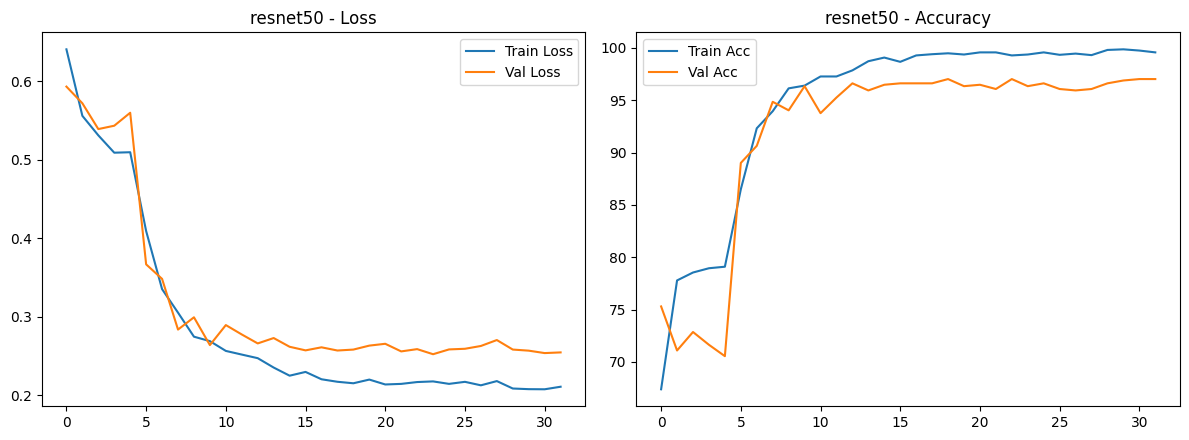

In [ ]:
history_resnet = train_one_model("resnet50")

## 12) خلية تشخيص شاملة قبل التقييم (تأكيد نهائي إن كل حاجة سليمة)
لازم تطلع الثلاثة موديلات ✅ قبل ما تكمّلي لخلية التقييم.

In [ ]:
import datetime

print("=" * 70)
print("فحص نهائي لكل الـ checkpoints قبل التقييم:")
print("=" * 70)

missing_models = []
for model_name in MODEL_NAMES:
    checkpoint_path = os.path.join(CHECKPOINTS_DIR, f"{model_name}_best.pt")
    if os.path.exists(checkpoint_path):
        size_mb = os.path.getsize(checkpoint_path) / (1024 ** 2)
        mtime = datetime.datetime.fromtimestamp(os.path.getmtime(checkpoint_path))
        try:
            _ = torch.load(checkpoint_path, map_location="cpu")
            status = "✅ سليم"
        except Exception:
            status = "❌ تالف (فشل التحميل)"
        print(f"{model_name}: {status} | الحجم={size_mb:.1f} MB | آخر تعديل={mtime}")
        if size_mb < 5:
            missing_models.append(model_name)
    else:
        print(f"❌ {model_name}: الملف مش موجود خالص")
        missing_models.append(model_name)

if missing_models:
    print(f"\n⚠️  لازم تعيدي تدريب: {missing_models} قبل ما تكمّلي (بعد التأكد من مساحة Drive في خلية 4).")
else:
    print("\n✅ الثلاثة موديلات سليمة وجاهزين للتقييم والـ Ensemble الكامل.")


فحص نهائي لكل الـ checkpoints قبل التقييم:
efficientnet_b3: ✅ سليم | الحجم=41.4 MB | آخر تعديل=2026-07-24 02:35:20
convnext_tiny: ✅ سليم | الحجم=106.2 MB | آخر تعديل=2026-07-24 03:07:37
resnet50: ✅ سليم | الحجم=90.0 MB | آخر تعديل=2026-07-24 03:49:49

✅ الثلاثة موديلات سليمة وجاهزين للتقييم والـ Ensemble الكامل.


## 13) التقييم النهائي: الموديلات المنفردة + Ensemble (Soft-Voting)

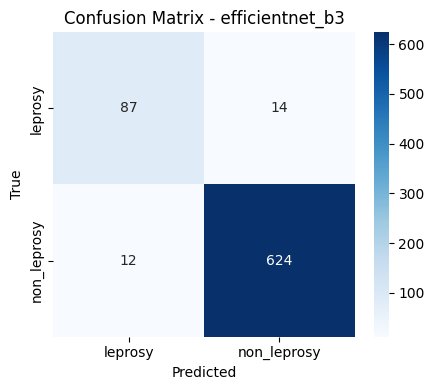

efficientnet_b3: Accuracy=96.47% | Recall(Leprosy)=86.14% | F1(Leprosy)=87.00%


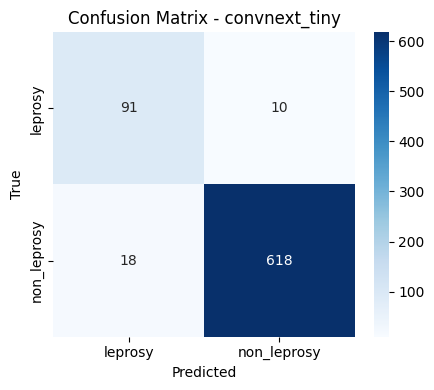

convnext_tiny: Accuracy=96.20% | Recall(Leprosy)=90.10% | F1(Leprosy)=86.67%


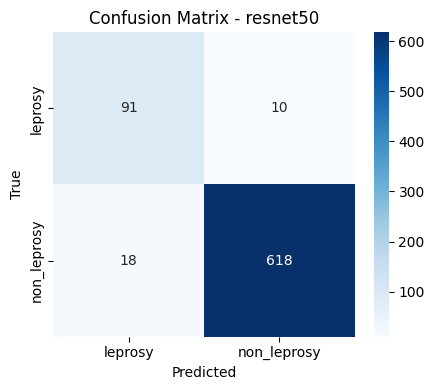

resnet50: Accuracy=96.20% | Recall(Leprosy)=90.10% | F1(Leprosy)=86.67%


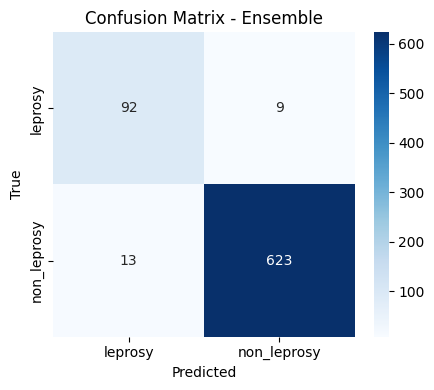

ENSEMBLE (3 models): Accuracy=97.01% | Recall(Leprosy)=91.09% | F1(Leprosy)=89.32%

جدول المقارنة النهائي:
                        Accuracy  Precision_Leprosy  Recall_Leprosy  F1_Leprosy
Model                                                                          
efficientnet_b3            96.47              87.88           86.14       87.00
convnext_tiny              96.20              83.49           90.10       86.67
resnet50                   96.20              83.49           90.10       86.67
ENSEMBLE (Soft-Voting)     97.01              87.62           91.09       89.32

تم حفظ الجدول في: /content/drive/MyDrive/skin_disease_project/outputs/results/final_comparison_table.csv


,Accuracy,Precision_Leprosy,Recall_Leprosy,F1_Leprosy
Model,,,,
efficientnet_b3,96.472185,87.878788,86.138614,87.000000
convnext_tiny,96.200814,83.486239,90.099010,86.666667
resnet50,96.200814,83.486239,90.099010,86.666667
ENSEMBLE (Soft-Voting),97.014925,87.619048,91.089109,89.320388


In [ ]:
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns


def get_all_probs_and_labels(model, loader, device):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            probs = F.softmax(outputs, dim=1).cpu().numpy()
            all_probs.append(probs)
            all_labels.append(labels.numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)


def compute_metrics(y_true, y_pred, leprosy_index):
    return {
        "Accuracy": accuracy_score(y_true, y_pred) * 100,
        "Precision_Leprosy": precision_score(y_true, y_pred, pos_label=leprosy_index, zero_division=0) * 100,
        "Recall_Leprosy": recall_score(y_true, y_pred, pos_label=leprosy_index, zero_division=0) * 100,
        "F1_Leprosy": f1_score(y_true, y_pred, pos_label=leprosy_index, zero_division=0) * 100,
    }


def plot_confusion(cm, classes, title, save_path):
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()


all_model_probs = {}
results_rows = []
true_labels = None

for model_name in MODEL_NAMES:
    checkpoint_path = os.path.join(CHECKPOINTS_DIR, f"{model_name}_best.pt")
    if not os.path.exists(checkpoint_path):
        print(f"⚠️  متلقيش checkpoint لـ {model_name} - دربيه الأول.")
        continue

    model, _ = build_model(model_name)
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    model.to(DEVICE)

    probs, labels = get_all_probs_and_labels(model, test_loader, DEVICE)
    all_model_probs[model_name] = probs
    true_labels = labels

    preds = probs.argmax(axis=1)
    metrics = compute_metrics(true_labels, preds, LEPROSY_INDEX)
    metrics["Model"] = model_name
    results_rows.append(metrics)

    cm = confusion_matrix(true_labels, preds)
    plot_confusion(cm, CLASSES, f"Confusion Matrix - {model_name}", os.path.join(PLOTS_DIR, f"cm_{model_name}.png"))

    print(f"{model_name}: Accuracy={metrics['Accuracy']:.2f}% | Recall(Leprosy)={metrics['Recall_Leprosy']:.2f}% "
          f"| F1(Leprosy)={metrics['F1_Leprosy']:.2f}%")

if len(all_model_probs) >= 2:
    stacked = np.stack(list(all_model_probs.values()), axis=0)
    avg_probs = stacked.mean(axis=0)
    ensemble_preds = avg_probs.argmax(axis=1)

    ensemble_metrics = compute_metrics(true_labels, ensemble_preds, LEPROSY_INDEX)
    ensemble_metrics["Model"] = "ENSEMBLE (Soft-Voting)"
    results_rows.append(ensemble_metrics)

    cm = confusion_matrix(true_labels, ensemble_preds)
    plot_confusion(cm, CLASSES, "Confusion Matrix - Ensemble", os.path.join(PLOTS_DIR, "cm_ensemble.png"))

    print(f"ENSEMBLE ({len(all_model_probs)} models): Accuracy={ensemble_metrics['Accuracy']:.2f}% | "
          f"Recall(Leprosy)={ensemble_metrics['Recall_Leprosy']:.2f}% | F1(Leprosy)={ensemble_metrics['F1_Leprosy']:.2f}%")
else:
    print("\n⚠️  محتاجة على الأقل موديلين متدربين عشان تعملي Ensemble.")

results_df = pd.DataFrame(results_rows).set_index("Model")[["Accuracy", "Precision_Leprosy", "Recall_Leprosy", "F1_Leprosy"]]
print("\nجدول المقارنة النهائي:")
print(results_df.round(2).to_string())

csv_path = os.path.join(RESULTS_DIR, "final_comparison_table.csv")
results_df.to_csv(csv_path)
print(f"\nتم حفظ الجدول في: {csv_path}")
results_df


# اكتشاف اخطاء تتطابق النواتج
الخلاصة والتوصية

✅ مفيش مشكلة في الكود، والنتائج صحيحة ويمكن الاعتماد عليها بثقة.

بس بما إنك عملتي التحقق ده بشكل منهجي وممتاز، أنصحك بحاجة واحدة بسيطة للبحث:

اذكري في قسم النتائج (أو كملاحظة/footnote) إن الموديلين طلعوا بنفس المتريكس الإجمالية بالصدفة رغم اختلاف الأوزان والتنبؤات الفردية (اتفاق 96.74% بس مش 100%)، وده بيوضح إنه مش duplicate run أو خطأ في المنهجية — ده بالظبط النوع من التوثيق اللي بيخلي البحث يبان دقيق ومتحقق منه بعناية، مش مجرد أرقام منسوخة.

In [ ]:
## تشخيص: هل convnext_tiny و resnet50 فعلاً بيدوا نفس النتيجة؟
import hashlib

print("=" * 70)
print("الخطوة 1: مقارنة الملفات نفسها على الديسك (هل هما فعلاً مختلفين؟)")
print("=" * 70)

def file_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

path_convnext = os.path.join(CHECKPOINTS_DIR, "convnext_tiny_best.pt")
path_resnet   = os.path.join(CHECKPOINTS_DIR, "resnet50_best.pt")

hash_convnext = file_md5(path_convnext)
hash_resnet   = file_md5(path_resnet)

print(f"MD5 convnext_tiny: {hash_convnext}")
print(f"MD5 resnet50     : {hash_resnet}")
print(f"هل الملفين متطابقين بالكامل؟ {hash_convnext == hash_resnet}")

print("\n" + "=" * 70)
print("الخطوة 2: تحميل الموديلين *من الصفر دلوقتي* ومقارنة الـ predictions الخام")
print("=" * 70)

model_convnext, _ = build_model("convnext_tiny")
model_convnext.load_state_dict(torch.load(path_convnext, map_location=DEVICE))
model_convnext.to(DEVICE)

model_resnet, _ = build_model("resnet50")
model_resnet.load_state_dict(torch.load(path_resnet, map_location=DEVICE))
model_resnet.to(DEVICE)

# فحص سريع: هل الأوزان الفعلية داخل الموديلين مختلفة؟
w_convnext = next(model_convnext.parameters()).detach().cpu().numpy().flatten()[:10]
w_resnet   = next(model_resnet.parameters()).detach().cpu().numpy().flatten()[:10]
print(f"أول 10 أوزان من convnext_tiny: {w_convnext}")
print(f"أول 10 أوزان من resnet50     : {w_resnet}")
print(f"هل الأوزان متطابقة؟ {np.allclose(w_convnext, w_resnet)}")

print("\n" + "=" * 70)
print("الخطوة 3: إعادة حساب الـ probabilities على test_loader من جديد (مش من الـ cache)")
print("=" * 70)

probs_convnext_fresh, labels_fresh = get_all_probs_and_labels(model_convnext, test_loader, DEVICE)
probs_resnet_fresh, _              = get_all_probs_and_labels(model_resnet, test_loader, DEVICE)

exact_match = np.array_equal(probs_convnext_fresh, probs_resnet_fresh)
close_match = np.allclose(probs_convnext_fresh, probs_resnet_fresh, atol=1e-4)

print(f"هل الـ probabilities الخام متطابقة تماماً (array_equal)? {exact_match}")
print(f"هل الـ probabilities قريبة جداً من بعض (allclose)? {close_match}")

preds_convnext = probs_convnext_fresh.argmax(axis=1)
preds_resnet   = probs_resnet_fresh.argmax(axis=1)
agreement = (preds_convnext == preds_resnet).mean() * 100
print(f"\nنسبة اتفاق الـ predictions بين الموديلين على كل صور الاختبار: {agreement:.2f}%")
print(f"عدد الصور اللي الموديلين اختلفوا فيها: {(preds_convnext != preds_resnet).sum()} من أصل {len(preds_convnext)}")

# مقارنة مباشرة مع الأرقام القديمة المطبوعة في الجدول
old_metrics_convnext = compute_metrics(labels_fresh, preds_convnext, LEPROSY_INDEX)
old_metrics_resnet   = compute_metrics(labels_fresh, preds_resnet, LEPROSY_INDEX)
print(f"\nconvnext_tiny (محسوبة الآن): {old_metrics_convnext}")
print(f"resnet50 (محسوبة الآن)     : {old_metrics_resnet}")

الخطوة 1: مقارنة الملفات نفسها على الديسك (هل هما فعلاً مختلفين؟)
MD5 convnext_tiny: d4f63b9383fc0658685e4f55936655e0
MD5 resnet50     : cfd033d0906b7b4d4a10ee5aeb7b0835
هل الملفين متطابقين بالكامل؟ False

الخطوة 2: تحميل الموديلين *من الصفر دلوقتي* ومقارنة الـ predictions الخام
أول 10 أوزان من convnext_tiny: [-0.1021053  -0.12598033 -0.07811285 -0.04917327  0.04894863 -0.0063131
 -0.02756647  0.00707051  0.00578944 -0.01698304]
أول 10 أوزان من resnet50     : [-0.01039911 -0.0056242   0.03515697 -0.06613856  0.04530163 -0.02389644
  0.00614473 -0.0581758   0.04396667  0.07729664]
هل الأوزان متطابقة؟ False

الخطوة 3: إعادة حساب الـ probabilities على test_loader من جديد (مش من الـ cache)
هل الـ probabilities الخام متطابقة تماماً (array_equal)? False
هل الـ probabilities قريبة جداً من بعض (allclose)? False

نسبة اتفاق الـ predictions بين الموديلين على كل صور الاختبار: 96.74%
عدد الصور اللي الموديلين اختلفوا فيها: 24 من أصل 737

convnext_tiny (محسوبة الآن): {'Accuracy': 96.20081411126186, 

## 14) مقارنة شاملة نهائية بين الموديلات + الـ Ensemble
جدول أداء + تعقيد، Bar Chart، ROC Curve، Confusion Matrices Grid، منحنيات تدريب متراكبة، والحكم النهائي.

مقارنة تعقيد وسرعة الموديلات:
                 Parameters_Millions  Size_MB  Inference_ms_per_image
Model                                                                
efficientnet_b3                10.70     41.4                    4.82
convnext_tiny                  27.82    106.2                    7.45
resnet50                       23.51     90.0                    5.76

الجدول الشامل النهائي (أداء + تعقيد):
                        Accuracy  Precision_Leprosy  Recall_Leprosy  F1_Leprosy  Parameters_Millions  Size_MB  Inference_ms_per_image
Model                                                                                                                                
efficientnet_b3            96.47              87.88           86.14       87.00                10.70     41.4                    4.82
convnext_tiny              96.20              83.49           90.10       86.67                27.82    106.2                    7.45
resnet50                   96.20             

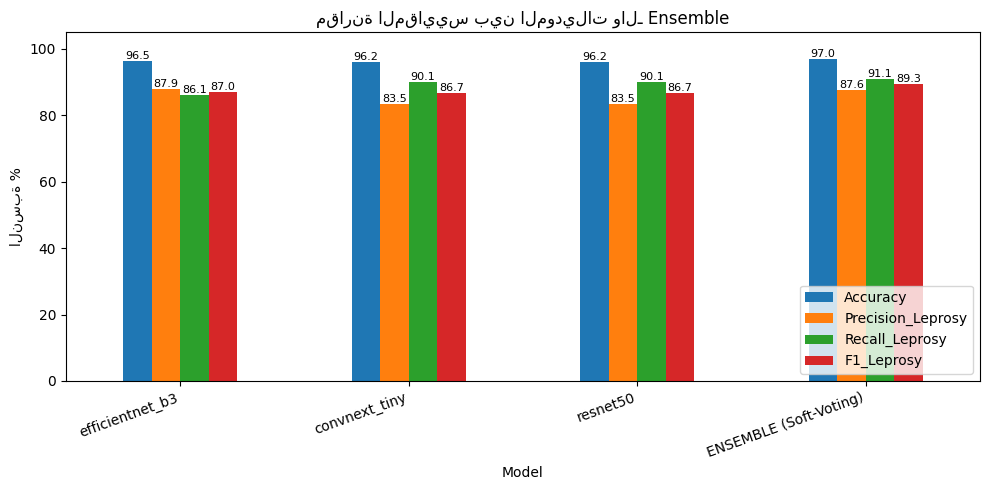

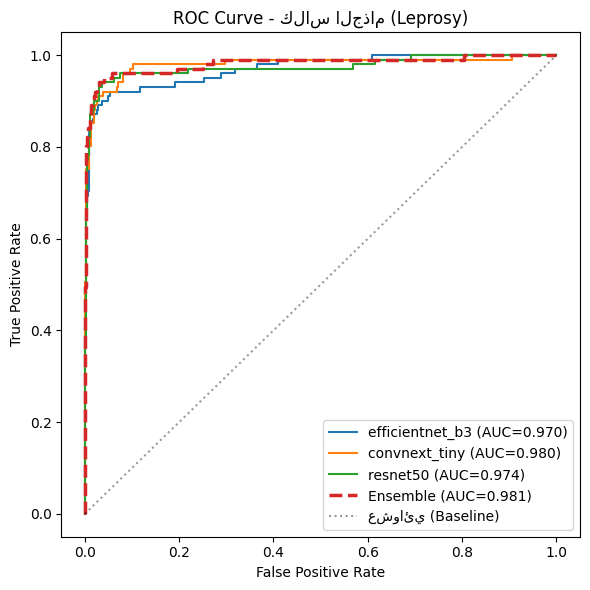

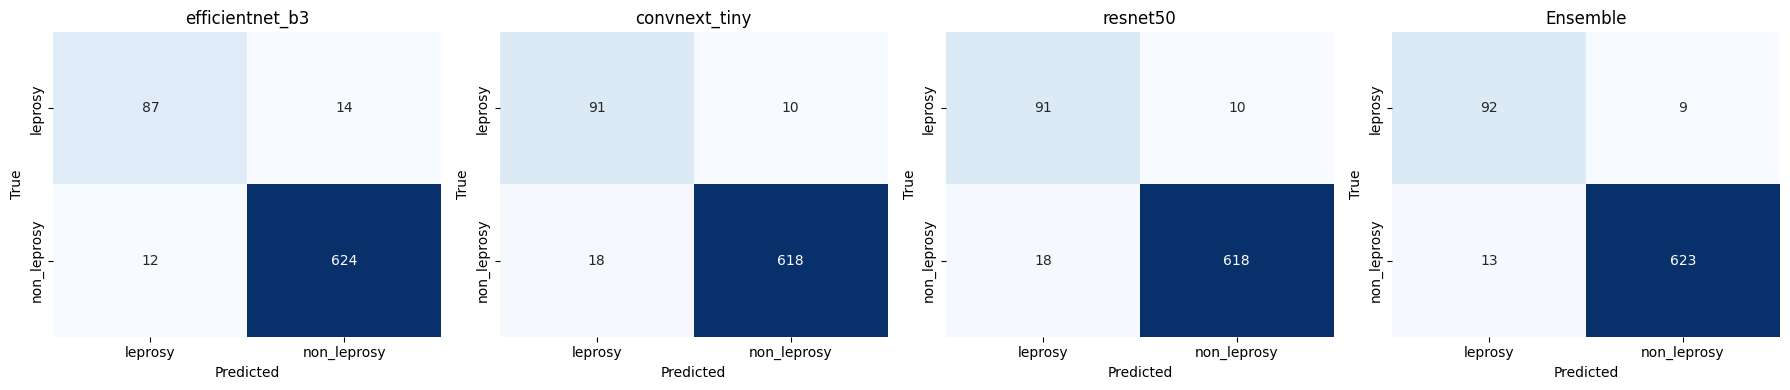

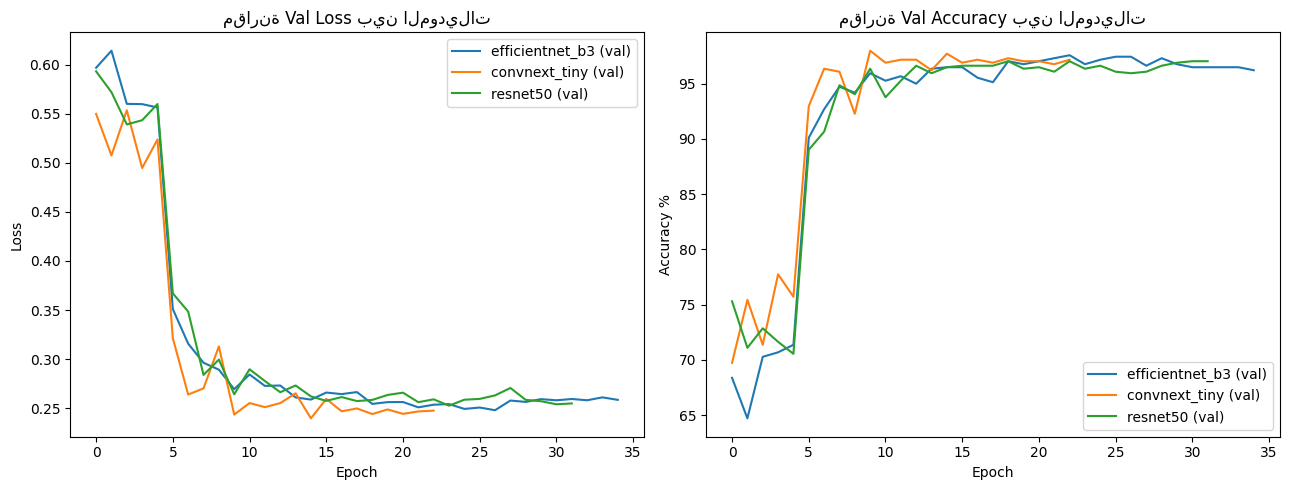


🏆 الحكم النهائي
أفضل أداء حسب F1-Score لكلاس الجذام: **ENSEMBLE (Soft-Voting)** (F1 = 89.32%)


,Accuracy,Precision_Leprosy,Recall_Leprosy,F1_Leprosy,Parameters_Millions,Size_MB,Inference_ms_per_image
Model,,,,,,,
efficientnet_b3,96.472185,87.878788,86.138614,87.000000,10.70,41.4,4.82
convnext_tiny,96.200814,83.486239,90.099010,86.666667,27.82,106.2,7.45
resnet50,96.200814,83.486239,90.099010,86.666667,23.51,90.0,5.76
ENSEMBLE (Soft-Voting),97.014925,87.619048,91.089109,89.320388,NaN,NaN,NaN


In [ ]:
import time as _time
from sklearn.metrics import roc_curve, auc

# ---- 1) عدد البارامترات + حجم الموديل + زمن الاستدلال ----
complexity_rows = []
for model_name in MODEL_NAMES:
    checkpoint_path = os.path.join(CHECKPOINTS_DIR, f"{model_name}_best.pt")
    if not os.path.exists(checkpoint_path):
        continue
    model, _ = build_model(model_name)
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()

    n_params = sum(p.numel() for p in model.parameters())
    size_mb = os.path.getsize(checkpoint_path) / (1024 ** 2)

    sample_batch, _ = next(iter(test_loader))
    sample_batch = sample_batch.to(DEVICE)
    with torch.no_grad():
        _ = model(sample_batch)
        torch.cuda.synchronize() if DEVICE.type == "cuda" else None
        start = _time.time()
        for _ in range(10):
            _ = model(sample_batch)
        torch.cuda.synchronize() if DEVICE.type == "cuda" else None
        elapsed = (_time.time() - start) / 10

    ms_per_image = (elapsed / sample_batch.size(0)) * 1000
    complexity_rows.append({
        "Model": model_name, "Parameters_Millions": round(n_params / 1e6, 2),
        "Size_MB": round(size_mb, 1), "Inference_ms_per_image": round(ms_per_image, 2),
    })

complexity_df = pd.DataFrame(complexity_rows).set_index("Model")
print("مقارنة تعقيد وسرعة الموديلات:")
print(complexity_df.to_string())

full_comparison = results_df.join(complexity_df, how="left")
print("\nالجدول الشامل النهائي (أداء + تعقيد):")
print(full_comparison.round(2).to_string())
full_comparison.to_csv(os.path.join(RESULTS_DIR, "full_comparison_table.csv"))

# ---- 2) Bar Chart ----
metrics_to_plot = ["Accuracy", "Precision_Leprosy", "Recall_Leprosy", "F1_Leprosy"]
fig, ax = plt.subplots(figsize=(10, 5))
results_df[metrics_to_plot].plot(kind="bar", ax=ax)
ax.set_title("مقارنة المقاييس بين الموديلات والـ Ensemble")
ax.set_ylabel("النسبة %")
ax.set_xticklabels(results_df.index, rotation=20, ha="right")
ax.legend(loc="lower right"); ax.set_ylim(0, 105)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "metrics_bar_comparison.png"), dpi=150)
plt.show()

# ---- 3) ROC Curve ----
plt.figure(figsize=(6, 6))
for model_name, probs in all_model_probs.items():
    fpr, tpr, _ = roc_curve(true_labels, probs[:, LEPROSY_INDEX], pos_label=LEPROSY_INDEX)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc:.3f})")
if len(all_model_probs) >= 2:
    fpr, tpr, _ = roc_curve(true_labels, avg_probs[:, LEPROSY_INDEX], pos_label=LEPROSY_INDEX)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Ensemble (AUC={roc_auc:.3f})", linewidth=2.5, linestyle="--")
plt.plot([0, 1], [0, 1], "k:", alpha=0.4, label="عشوائي (Baseline)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - كلاس الجذام (Leprosy)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "roc_curves_comparison.png"), dpi=150)
plt.show()

# ---- 4) Confusion Matrices Grid ----
all_preds_dict = {name: probs.argmax(axis=1) for name, probs in all_model_probs.items()}
if len(all_model_probs) >= 2:
    all_preds_dict["Ensemble"] = avg_probs.argmax(axis=1)

n_models = len(all_preds_dict)
fig, axes = plt.subplots(1, n_models, figsize=(4.5 * n_models, 4))
if n_models == 1:
    axes = [axes]
for ax, (name, preds) in zip(axes, all_preds_dict.items()):
    cm = confusion_matrix(true_labels, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "all_confusion_matrices_grid.png"), dpi=150)
plt.show()

# ---- 5) منحنيات التدريب المتراكبة ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
histories = {}
for model_name in MODEL_NAMES:
    log_path = os.path.join(LOGS_DIR, f"{model_name}_history.json")
    if not os.path.exists(log_path):
        continue
    with open(log_path) as f:
        histories[model_name] = json.load(f)
for model_name, h in histories.items():
    axes[0].plot(h["val_loss"], label=f"{model_name} (val)")
    axes[1].plot(h["val_acc"], label=f"{model_name} (val)")
axes[0].set_title("مقارنة Val Loss بين الموديلات"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[1].set_title("مقارنة Val Accuracy بين الموديلات"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy %"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "training_curves_comparison.png"), dpi=150)
plt.show()

# ---- 6) الحكم النهائي ----
best_model = results_df["F1_Leprosy"].idxmax()
best_f1 = results_df.loc[best_model, "F1_Leprosy"]
print("\n" + "=" * 70)
print("🏆 الحكم النهائي")
print("=" * 70)
print(f"أفضل أداء حسب F1-Score لكلاس الجذام: **{best_model}** (F1 = {best_f1:.2f}%)")
if best_model != "ENSEMBLE (Soft-Voting)" and "ENSEMBLE (Soft-Voting)" in results_df.index:
    ens_f1 = results_df.loc["ENSEMBLE (Soft-Voting)", "F1_Leprosy"]
    diff = ens_f1 - best_f1
    if diff > 0:
        print(f"ملحوظة: الـ Ensemble حسّن الـ F1 بمقدار {diff:.2f} نقطة عن أفضل موديل منفرد.")
    else:
        print(f"ملحوظة: الـ Ensemble ماحسنش عن أفضل موديل منفرد في الحالة دي (فرق {diff:.2f}).")

full_comparison
